In [314]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [315]:
from google.colab import files
upload = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (4).csv


In [362]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [363]:
df.shape

(7043, 21)

In [364]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4265,2632-UCGVD,Male,1,Yes,No,66,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.05,6871.9,Yes
5889,9693-XMUOB,Male,1,Yes,No,59,No,No phone service,DSL,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,50.25,2997.45,No
1201,6789-HJBWG,Female,0,No,No,12,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,49.40,611.65,No
5284,3317-HRTNN,Female,1,No,No,5,No,No phone service,DSL,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,45.70,198,Yes
3913,8749-TZYEC,Male,0,Yes,No,72,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),24.80,1874.3,No


In [365]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Here 18 row are object, 2 int types , 1 float dtype row

In [366]:
#checking for the null values
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [367]:
#checking for the duplicates
df.duplicated().sum()

np.int64(0)

No missing values presents, no duplicates are present

In [368]:
#converting the object columns to the numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [369]:
df['TotalCharges'].head(5)

,TotalCharges
0,29.85
1,1889.50
2,108.15
3,1840.75
4,151.65


converting other cat columns


In [370]:
categorical_columns = df.select_dtypes(include=['object']).columns
print(categorical_columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')


In [371]:
bin_columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in bin_columns:
    df[col] = df[col].map({'Yes': 1, 'No': 0 , "Male": 1, "Female": 0})
#mapping the binary columns

In [372]:
#Target Columns
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [373]:
df['Churn']

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [374]:
#Encoding the left category columns
df.drop(columns=['customerID'] , inplace=True)
cat_columns = df.select_dtypes(include=['object']).columns
print(cat_columns)

Index(['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaymentMethod'],
      dtype='object')


In [375]:
df=pd.get_dummies(df, columns=cat_columns , drop_first=True, dtype=int)

In [376]:
print(df.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [377]:
percentage = df["Churn"].value_counts(normalize=True)* 100

In [378]:
df['Churn'].head(5)

,Churn
0,0
1,0
2,1
3,0
4,1


In [379]:
print(percentage)

Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


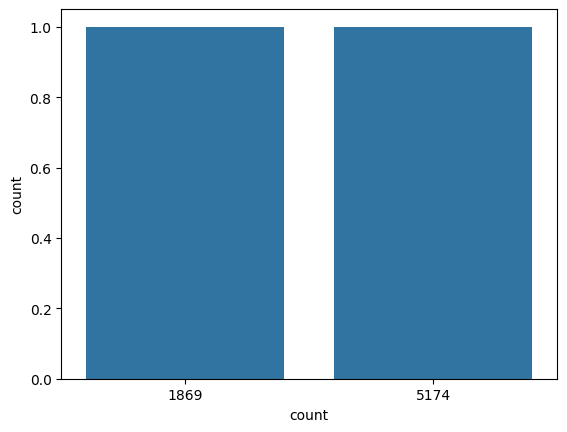

In [380]:
sns.countplot(df , x =df["Churn"].value_counts())
plt.show()

In [381]:
df.groupby("Contract")[["MonthlyCharges" , "tenure"]].mean()

KeyError: 'Contract'

In [357]:
top_5 = df.sort_values(by="TotalCharges" , ascending=False).head(5)


In [359]:
avg_charges = df.groupby('PaperlessBilling')['MonthlyCharges'].mean()
print(avg_charges)

PaperlessBilling
0    51.992967
1    73.553776
Name: MonthlyCharges, dtype: float64


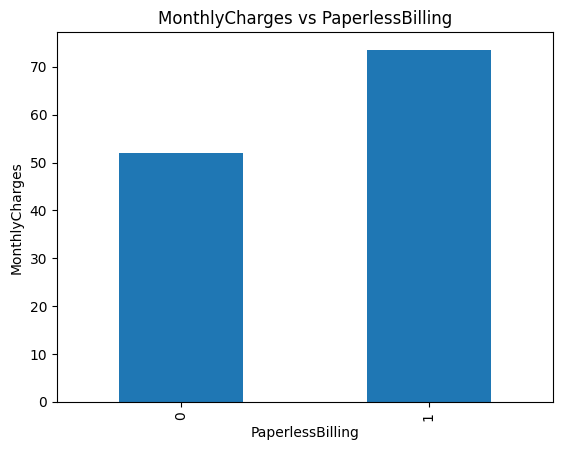

In [277]:
avg_charges.plot(kind='bar')
plt.title('MonthlyCharges vs PaperlessBilling')
plt.xlabel('PaperlessBilling')
plt.ylabel('MonthlyCharges')
plt.show()

In [278]:
#creating col
df['AvgChargesPerMonth']=(df['TotalCharges']/df['tenure']+1 )
#creating avg for churned and non-vhurned
avg_churn = df.groupby('Churn')['AvgChargesPerMonth'].mean()
print(avg_churn)

Churn
0    62.312024
1    75.433154
Name: AvgChargesPerMonth, dtype: float64


In [279]:
df =df.drop(columns=['customerID'])

KeyError: "['customerID'] not found in axis"

In [280]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   gender              7043 non-null   int64   
 1   SeniorCitizen       7043 non-null   int64   
 2   Partner             7043 non-null   int64   
 3   Dependents          7043 non-null   int64   
 4   tenure              7043 non-null   int64   
 5   PhoneService        7043 non-null   int64   
 6   MultipleLines       7043 non-null   object  
 7   InternetService     7043 non-null   object  
 8   OnlineSecurity      7043 non-null   object  
 9   OnlineBackup        7043 non-null   object  
 10  DeviceProtection    7043 non-null   object  
 11  TechSupport         7043 non-null   object  
 12  StreamingTV         7043 non-null   object  
 13  StreamingMovies     7043 non-null   object  
 14  Contract            7043 non-null   object  
 15  PaperlessBilling    7043 non-null   in

In [281]:
#seperating the features
X = df.drop('Churn', axis=1)
y = df['Churn']

In [282]:
#train-test_split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [283]:
scaler = StandardScaler()

In [284]:
X_train[num_cols]= scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [285]:
#feature engineering
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 12, 24, float('inf')], labels=['0-12', '13-24', '>24'])

In [286]:
#Model traing
#1.Baseline logistiRegression
from sklearn.linear_model import LogisticRegression


In [287]:
#modelling for the logistic regression
logReg  = LogisticRegression()
logReg.fit(X_train , y_train)

ValueError: could not convert string to float: 'No'